## ML Gymnasium Environment — ATCEnv v2

In [6]:
%pip install gymnasium


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Chargement du tenseur

In [7]:
import torch
import warnings
warnings.filterwarnings('ignore')

initial_states_tensor = torch.load("initial_states.pt", weights_only=True)
print(f"Tenseur chargé. Shape : {initial_states_tensor.shape}")

Tenseur chargé. Shape : torch.Size([43, 6])


## ATCEnv v2 — Environnement Gymnasium amélioré

Améliorations par rapport à la version précédente :
- **Physique corrigée** (rotation de cap réaliste, montée/descente propre)
- **Condition de succès** (`terminated=True` quand conflit résolu)
- **Récompense sur la séparation verticale**
- **Pénalité légère sur les manœuvres non-nécessaires**
- **Info dict** : `{collision, success}`

In [8]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np

class ATCEnv(gym.Env):
    """
    Environnement de résolution de conflits aériens (ATC) — Version 2.
    
    État : [dx, dy, dz, dvx, dvy, dvz] normalisés (Z-score)
      - dx, dy, dz  : séparation relative en position (NM normalisés)
      - dvx, dvy, dvz : vitesse relative (m/s normalisés)
    
    Actions (Discrete 5) :
      0 : Maintenir la trajectoire
      1 : Virage à droite (+15°)
      2 : Virage à gauche  (-15°)
      3 : Monter (+1000 ft/min de taux de montée)
      4 : Descendre (-1000 ft/min)
    
    Terminaison :
      - Collision (terminated=True, reward=-50)
      - Conflit résolu (terminated=True, reward=+100)
      - Temps écoulé (truncated=True, max_steps=60)
    """
    
    metadata = {"render_modes": []}
    
    # Seuils en espace normalisé (calculés d'après la StandardScaler du feature engineering)
    COLLISION_HORIZ = 0.15   # ~0.15 écart-type ≈ collision imminente
    COLLISION_VERT  = 0.15
    SAFE_HORIZ      = 2.0    # Séparation horizontale confortable
    SAFE_VERT       = 1.0    # Séparation verticale confortable
    
    def __init__(self, initial_states_tensor, max_steps=60, dt=10.0):
        super(ATCEnv, self).__init__()
        
        self.initial_states = initial_states_tensor.numpy()  # (N, 6)
        self.max_steps = max_steps
        self.dt = dt  # Durée d'un pas de temps en secondes
        
        # === ESPACES ===
        self.action_space = spaces.Discrete(5)
        self.observation_space = spaces.Box(
            low=-10.0, high=10.0, shape=(6,), dtype=np.float32
        )
        
        # État interne
        self.state = None
        self.current_step = 0
        self.prev_dist_horiz = 0.0
        self.prev_dist_vert  = 0.0

    # ------------------------------------------------------------------
    def reset(self, seed=None, options=None):
        """Initialise un nouvel épisode en piochant un scénario au hasard."""
        super().reset(seed=seed)
        
        # Sélection aléatoire d'un des 43 scénarios de conflit
        idx = self.np_random.integers(len(self.initial_states))
        self.state = self.initial_states[idx].copy().astype(np.float32)
        self.current_step = 0
        
        dx, dy, dz, _, _, _ = self.state
        self.prev_dist_horiz = float(np.hypot(dx, dy))
        self.prev_dist_vert  = float(abs(dz))
        
        return self.state, {}

    # ------------------------------------------------------------------
    def step(self, action):
        """Applique une manœuvre et retourne le nouvel état, la récompense et les flags."""
        dx, dy, dz, dvx, dvy, dvz = self.state
        
        # === 1. MISE À JOUR CINÉMATIQUE SELON L'ACTION ===
        
        if action == 1:  # Virage à droite : rotation de +15° du vecteur vitesse horizontal
            theta = np.radians(15.0)
            dvx, dvy = (dvx * np.cos(theta) - dvy * np.sin(theta),
                        dvx * np.sin(theta) + dvy * np.cos(theta))
            
        elif action == 2:  # Virage à gauche : rotation de -15°
            theta = np.radians(-15.0)
            dvx, dvy = (dvx * np.cos(theta) - dvy * np.sin(theta),
                        dvx * np.sin(theta) + dvy * np.cos(theta))
            
        elif action == 3:  # Montée : augmentation du taux de montée vertical
            dvz += 0.1
            
        elif action == 4:  # Descente : diminution du taux de montée vertical
            dvz -= 0.1
        # action == 0 : maintien de trajectoire, aucun changement
        
        # === 2. PROPAGATION DE LA POSITION (physique dt) ===
        scale = self.dt / 60.0  # Facteur de conversion (10s → fraction de minute)
        dx += dvx * scale
        dy += dvy * scale
        dz += dvz * scale
        
        self.state = np.array([dx, dy, dz, dvx, dvy, dvz], dtype=np.float32)
        
        # === 3. CALCUL DES DISTANCES ===
        curr_dist_horiz = float(np.hypot(dx, dy))
        curr_dist_vert  = float(abs(dz))
        
        # === 4. FONCTION DE RÉCOMPENSE ===
        reward     = 0.0
        terminated = False
        collision  = False
        success    = False
        
        if curr_dist_horiz < self.COLLISION_HORIZ and curr_dist_vert < self.COLLISION_VERT:
            # --- Collision : pénalité sévère ---
            reward    -= 50.0
            terminated = True
            collision  = True
            
        elif curr_dist_horiz >= self.SAFE_HORIZ and curr_dist_vert >= self.SAFE_VERT:
            # --- Conflit résolu : bonus de succès ---
            reward    += 100.0
            terminated = True
            success    = True
            
        else:
            # --- Récompense de progrès ---
            # Progrès horizontal (principal objectif ATC)
            delta_horiz = curr_dist_horiz - self.prev_dist_horiz
            reward += delta_horiz * 5.0
            
            # Progrès vertical (séparation verticale aussi importante)
            delta_vert = curr_dist_vert - self.prev_dist_vert
            reward += delta_vert * 2.0
            
            # Bonus de confort si bonne séparation maintenue
            if curr_dist_horiz > 1.5:
                reward += 0.5
        
        # Pénalité de temps (incite à résoudre rapidement)
        reward -= 0.05
        
        # Légère pénalité sur les manœuvres inutiles
        if action != 0:
            reward -= 0.02
        
        # === 5. MISE À JOUR DE L'ÉTAT INTERNE ===
        self.prev_dist_horiz = curr_dist_horiz
        self.prev_dist_vert  = curr_dist_vert
        self.current_step   += 1
        truncated = self.current_step >= self.max_steps
        
        info = {"collision": collision, "success": success,
                "dist_horiz": curr_dist_horiz, "dist_vert": curr_dist_vert}
        
        return self.state, reward, terminated, truncated, info

## Test de l'environnement — Agent aléatoire

=== Résultats sur 100 épisodes (agent aléatoire) ===
Récompense moyenne    : 81.69 ± 58.43
Récompense max/min    : 151.66 / -50.07
Nombre de collisions  : 13 / 100
Conflits résolus      : 73 / 100


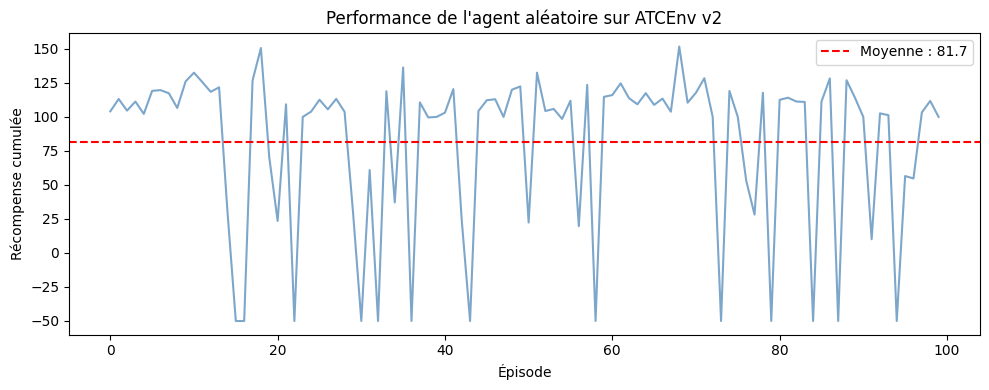

In [9]:
import matplotlib.pyplot as plt

env = ATCEnv(initial_states_tensor)

# --- Test sur 100 épisodes avec un agent aléatoire ---
n_episodes = 100
episode_rewards = []
collision_count = 0
success_count   = 0

for ep in range(n_episodes):
    obs, info = env.reset()
    total_reward = 0.0
    done = False
    
    while not done:
        action = env.action_space.sample()
        obs, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        done = terminated or truncated
    
    episode_rewards.append(total_reward)
    if info.get("collision"):
        collision_count += 1
    if info.get("success"):
        success_count += 1

print("=== Résultats sur 100 épisodes (agent aléatoire) ===")
print(f"Récompense moyenne    : {np.mean(episode_rewards):.2f} \u00b1 {np.std(episode_rewards):.2f}")
print(f"Récompense max/min    : {max(episode_rewards):.2f} / {min(episode_rewards):.2f}")
print(f"Nombre de collisions  : {collision_count} / {n_episodes}")
print(f"Conflits résolus      : {success_count} / {n_episodes}")

plt.figure(figsize=(10, 4))
plt.plot(episode_rewards, alpha=0.7, color='steelblue')
plt.axhline(np.mean(episode_rewards), color='red', linestyle='--', label=f"Moyenne : {np.mean(episode_rewards):.1f}")
plt.xlabel("\u00c9pisode")
plt.ylabel("R\u00e9compense cumul\u00e9e")
plt.title("Performance de l'agent al\u00e9atoire sur ATCEnv v2")
plt.legend()
plt.tight_layout()
plt.show()

## Vérification d'un épisode détaillé

In [10]:
env = ATCEnv(initial_states_tensor, max_steps=60)
obs, info = env.reset(seed=42)

print("--- D\u00c9BUT DE L'\u00c9PISODE ---")
print(f"\u00c9tat initial (observation normalis\u00e9e) : {obs}\n")

total_reward = 0.0
done = False
step_count = 0
action_names = ["Maintenir", "Virage droite", "Virage gauche", "Monter", "Descendre"]

while not done:
    action = env.action_space.sample()
    next_obs, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    step_count += 1
    done = terminated or truncated
    
    status = "COLLISION !" if info["collision"] else ("SUCC\u00c8S !" if info["success"] else "")
    print(f"Pas {step_count:02d} | {action_names[action]:<14} | Reward: {reward:+.2f} | "
          f"H={info['dist_horiz']:.2f} V={info['dist_vert']:.2f} | {status}")

print(f"\n--- FIN DE L'\u00c9PISODE ---")
print(f"Nombre total de pas    : {step_count}")
print(f"R\u00e9compense cumul\u00e9e     : {total_reward:.2f}")
print(f"Collision : {info['collision']} | Succ\u00e8s : {info['success']}")

--- DÉBUT DE L'ÉPISODE ---
État initial (observation normalisée) : [ 1.2094834  -0.5873313   0.0164351  -0.41805166 -0.23425373  0.15028316]

Pas 01 | Maintenir      | Reward: -0.22 | H=1.30 V=0.04 | 
Pas 02 | Maintenir      | Reward: -0.20 | H=1.26 V=0.07 | 
Pas 03 | Descendre      | Reward: -0.24 | H=1.22 V=0.07 | 
Pas 04 | Maintenir      | Reward: -0.19 | H=1.19 V=0.08 | 
Pas 05 | Monter         | Reward: -0.16 | H=1.16 V=0.11 | 
Pas 06 | Maintenir      | Reward: -0.11 | H=1.14 V=0.13 | 
Pas 07 | Descendre      | Reward: -0.14 | H=1.12 V=0.14 | 
Pas 08 | Descendre      | Reward: -0.15 | H=1.11 V=0.13 | 
Pas 09 | Virage gauche  | Reward: -0.22 | H=1.08 V=0.13 | 
Pas 10 | Virage gauche  | Reward: -0.29 | H=1.04 V=0.12 | 
Pas 11 | Descendre      | Reward: -0.30 | H=1.01 V=0.09 | 
Pas 12 | Virage droite  | Reward: -0.17 | H=1.00 V=0.07 | 
Pas 13 | Virage gauche  | Reward: -0.25 | H=0.97 V=0.04 | 
Pas 14 | Descendre      | Reward: -0.25 | H=0.95 V=0.00 | 
Pas 15 | Virage gauche  | Reward